# Summer 2026 in Europe: heat and drought at NUTS 2 level

Was the summer of 2026 an exceptional event, or simply the next step in a long-term warming trend? And which European regions went through a similar mix of heat and drought? These two questions guide the whole project.

The notebook follows the analysis from start to finish: description of the data, exploratory analysis, clustering, final figures, export for the Power BI dashboard and conclusion. The reusable code (data loading, aggregation, indicators, statistics) is kept in the `src/climate_europe/` package, so that the notebook can focus on the analysis itself.

*We acknowledge the E-OBS dataset from the Copernicus Climate Change Service, and the data providers in the ECA&D project (https://www.ecad.eu); Cornes et al. (2018), J. Geophys. Res. Atmos., 123, doi:10.1029/2017JD028200.*

## 0. Setup
Libraries, project settings (read from `config.yaml`) and plotting style.

In [1]:
import os

os.environ.setdefault("OMP_NUM_THREADS", "2")  # limits the threads used by KMeans (avoids a known scikit-learn warning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from climate_europe import viz
from climate_europe.config import load_config

cfg = load_config()
RECOMPUTE = False  # True = redo the grid -> region aggregation (about 3 min) instead of reading the cache
YEAR = 2026
REF = tuple(cfg["analysis"]["reference_period"])
TREND = tuple(cfg["analysis"]["trend_period"])
FIG = cfg["root"] / "reports" / "figures"
INTERIM = cfg["paths"]["interim_dir"]

viz.set_style()
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 30)

# 1. Introduction and data description

## 1.1 Context
Heatwaves have become a familiar part of European summers. 2003, 2010 (in eastern Europe), 2018, 2022 and 2024 all broke regional records, and most of them came with drought. Summer 2026 was another very hot one, and it is the starting point of this project. Rather than taking for granted that it was exceptional, we compare it with 46 years of observations (1980-2025) and with the 1991-2020 climate normal, the current WMO reference period.

The notebook is organised as follows:
1. description of the datasets and of the main methodological choices;
2. exploratory data analysis, leading to five research questions (Q1-Q5);
3. clustering of the regions according to their heat and drought profile;
4. one final figure per question, and export of the tables used in the Power BI dashboard;
5. conclusion and limits of the approach.

## 1.2 Datasets

| Dataset | Content | Resolution | Period | Source |
|---|---|---|---|---|
| E-OBS v33.0e, ensemble mean | daily `tg` mean, `tn` min, `tx` max temperature (°C), `rr` precipitation (mm) | 0.25° regular grid (about 28 x 18 km at 50°N) | 1980-2025 | Copernicus C3S / ECA&D |
| E-OBS monthly updates | same variables, provisional | same grid | Jan-Sep 2026 | idem |
| NUTS 2024 (GISCO) | boundaries of administrative regions, level 2 | 1:1 million | - | Eurostat |

**Data dictionary.** The tables derived from these data (section 2) use the following columns:

| Column | Unit | Definition |
|---|---|---|
| `region_id`, `name`, `country` | - | NUTS 2 code, Latin name, country code (EL = Greece) |
| `date` / `year` | - | day / year |
| `tg`, `tn`, `tx`, `rr` | °C, mm | regional daily mean of the E-OBS cells (weighted, see 2.1) |
| `summer_tg`, `summer_tx`, `summer_tn` | °C | June-August mean |
| `summer_*_anomaly` | °C | minus the 1991-2020 June-August mean of the same region |
| `hot_days_30`, `hot_days_35` | days | days with `tx` > 30 / 35 °C |
| `hot_days_p90` | days | days with `tx` above the region's 90th percentile of 1991-2020 summer days |
| `tropical_nights` | days | nights with `tn` > 20 °C |
| `heatwave_count`, `heatwave_days`, `heatwave_max_length` | -, days | runs of ≥ 3 consecutive days above the local p90 |
| `heatwave_intensity` | °C | mean excess of `tx` over the local p90 during heatwave days |
| `summer_rr`, `summer_rr_anomaly` | mm, % | June-August total, anomaly in % of 1991-2020 (not computed when the normal is below 10 mm) |
| `max_consecutive_dry_days` | days | longest run with `rr` < 1 mm in June-August |
| `drought_index` | - | SPEI-3 of August (water balance June-August), standardised on 1991-2020, clipped to ±3 |
| `coverage` | share | share of summer days with valid data |

In [2]:
from climate_europe.loaders.eobs import EobsLoader
from climate_europe.loaders.nuts import NutsLoader

regions = NutsLoader(cfg).load()
centroids = regions.to_crs(viz.MAP_CRS).centroid.to_crs(4326)  # centroid computed in an equal-area projection
regions["latitude"], regions["longitude"] = centroids.y.values, centroids.x.values
regions["area_km2"] = regions.to_crs(viz.MAP_CRS).area.values / 1e6
print(f"{len(regions)} NUTS 2 regions in {regions['country'].nunique()} countries")
regions.drop(columns="geometry").head()

19:19:38 | loader.nuts | INFO | Start loading nuts


19:19:38 | loader.nuts | INFO | 1 file(s) found


19:19:39 | loader.nuts | INFO | 284 NUTS 2 regions kept


19:19:39 | loader.nuts | INFO | Loading finished


284 NUTS 2 regions in 37 countries


,region_id,name,country,latitude,longitude,area_km2
0,AT11,Burgenland,AT,47.54,16.52,3965.38
1,AT33,Tirol,AT,47.20,11.50,12651.06
2,AT34,Vorarlberg,AT,47.24,9.89,2619.02
3,BE22,Prov. Limburg (BE),BE,50.99,5.43,2426.57
4,BG34,Yugoiztochen,BG,42.47,26.54,19799.98


In [3]:
grid = EobsLoader(cfg).load()
grid

19:19:39 | loader.eobs | INFO | Start loading eobs


19:19:39 | loader.eobs | INFO | 48 file(s) found


19:19:39 | loader.eobs | INFO | Opening tg (12 files)


19:19:40 | loader.eobs | INFO | Opening tn (12 files)


19:19:40 | loader.eobs | INFO | Opening tx (12 files)


19:19:40 | loader.eobs | INFO | Opening rr (12 files)


19:19:40 | loader.eobs | INFO | E-OBS grid {'time': 17075, 'lat': 201, 'lon': 464}, 1980-01-01 to 2026-09-30


19:19:40 | loader.eobs | INFO | Loading finished


<xarray.Dataset> Size: 25GB
Dimensions:  (time: 17075, lat: 201, lon: 464)
Coordinates:
  * time     (time) datetime64[ns] 137kB 1980-01-01 1980-01-02 ... 2026-09-30
  * lat      (lat) float64 2kB 25.38 25.62 25.88 26.12 ... 74.88 75.12 75.38
  * lon      (lon) float64 4kB -40.38 -40.12 -39.88 -39.62 ... 74.88 75.12 75.38
Data variables:
    tg       (time, lat, lon) float32 6GB dask.array<chunksize=(365, 201, 464), meta=np.ndarray>
    tn       (time, lat, lon) float32 6GB dask.array<chunksize=(365, 201, 464), meta=np.ndarray>
    tx       (time, lat, lon) float32 6GB dask.array<chunksize=(365, 201, 464), meta=np.ndarray>
    rr       (time, lat, lon) float32 6GB dask.array<chunksize=(365, 201, 464), meta=np.ndarray>
Attributes:
    E-OBS_version:  33.0e
    Conventions:    CF-1.4
    References:     http://surfobs.climate.copernicus.eu/dataaccess/access_eo...
    history:        Tue Mar 10 17:53:48 2026: ncks -O --no-abc -d time,10957,...
    NCO:            netCDF Operators version 5.3.3 (Homepage = http://nco.sf....

In [4]:
sample_day = f"{YEAR}-07-15"
pd.DataFrame(
    {
        v: {
            "long_name": grid[v].attrs.get("long_name"),
            "units": grid[v].attrs.get("units"),
            f"cells with data on {sample_day}": int(grid[v].sel(time=sample_day).notnull().sum()),
        }
        for v in grid.data_vars
    }
).T

,long_name,units,cells with data on 2026-07-15
tg,mean temperature,Celsius,19248
tn,minimum temperature,Celsius,19318
tx,maximum temperature,Celsius,19449
rr,rainfall,mm,18345


The E-OBS grid is large: four variables over 17,075 days on a 201 x 464 grid represent about 25 GB once loaded. We therefore open it lazily with dask and process it one year at a time.

The map below puts the raw grid on top of the NUTS boundaries. The left panel shows the whole domain; the right one zooms in on the Benelux, where some regions are smaller than a single grid cell (Brussels covers about 160 km²).

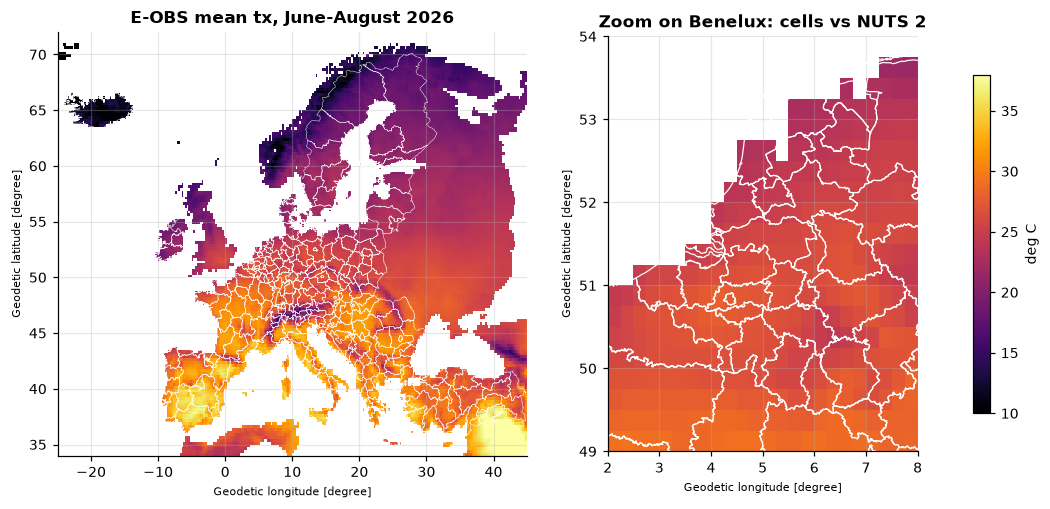

In [5]:
summer_tx = grid["tx"].sel(time=slice(f"{YEAR}-06-01", f"{YEAR}-08-31")).mean("time").compute()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
for ax, (lon, lat) in zip(axes, [((-25, 45), (34, 72)), ((2, 8), (49, 54))]):
    sub = summer_tx.sel(lon=slice(*lon), lat=slice(*lat))
    mesh = ax.pcolormesh(sub["lon"], sub["lat"], sub, cmap="inferno", vmin=10, vmax=38, shading="nearest")
    regions.boundary.plot(ax=ax, color="white", linewidth=0.3 if ax is axes[0] else 0.8)
    ax.set_xlim(lon); ax.set_ylim(lat); ax.set_aspect(1 / np.cos(np.deg2rad(np.mean(lat))))
axes[0].set_title(f"E-OBS mean tx, June-August {YEAR}")
axes[1].set_title("Zoom on Benelux: cells vs NUTS 2")
fig.colorbar(mesh, ax=axes, shrink=0.8, label="deg C")
viz.save(fig, FIG, "01_grid_vs_regions")

## 1.3 Methodological choices
* **Grid resolution: 0.25° rather than 0.1°.** We work at the scale of NUTS 2 regions, and a region contains on average about 40 cells of the 0.25° grid. The 0.1° product does not contain more information: it is interpolated from the same stations, and the quality of E-OBS is limited by station density rather than by grid size (Cornes et al., 2018). At regional scale, the finer grid would mostly multiply the data volume by six and give a false impression of precision.
* **Ensemble mean.** E-OBS is provided as a 20-member ensemble. We use the ensemble mean, which is the best estimate and the version used in most studies. The spread measures the interpolation uncertainty; once tens of cells are averaged within a region, most of it cancels out. It is not used in the main analysis, but it could serve as a robustness check.
* **Reference period 1991-2020.** This is the current WMO climate normal. Anomalies are therefore measured against a climate that is already warmer than that of the 1980s.
* **Summer = June, July and August.** This is the meteorological summer, as used in the Copernicus and ECMWF seasonal bulletins.
* **Drought index computed from E-OBS.** SPEIbase ends in 2024 and cannot describe 2026. Computing a SPEI-like index from E-OBS (section 2.1) also means that heat and drought are derived from the same data.
* **Provisional 2026 data.** The monthly updates rely on fewer stations than the full release and may still be revised.
* **Spatial coverage.** The UK is no longer part of NUTS 2024 after Brexit and is therefore missing. We added Bosnia and Herzegovina (BA) and Kosovo (XK) to avoid a gap in the Balkans. The outermost regions (Canary Islands, Azores, Madeira, French overseas regions) lie outside the E-OBS domain.

# 2. Exploratory data analysis

## 2.1 Regional aggregation and indicators
We first move from grid cells to NUTS 2 regions, then compute summer indicators for every region and every year.

**Aggregation rule** (`RegionalAggregator`). Each cell contributes to a region with a weight equal to the fraction of the cell that lies inside the region (computed with `regionmask` on a 10 x 10 sub-grid), multiplied by cos(latitude) to account for the cell area. On a given day, cells without data (sea, missing stations) are simply ignored. Using fractions rather than a "cell centre inside the polygon" rule matters for small regions such as Brussels, which contain no cell centre at all. Regions covered by less than 0.1 cell of valid data are dropped (Malta, Ceuta and Melilla). This step is the slowest of the project, so it is run once and its result is saved in `data/interim`.

In [6]:
from climate_europe.processing.spatial import RegionalAggregator

daily_path = INTERIM / "regional_daily.parquet"
if RECOMPUTE or not daily_path.exists():
    aggregator = RegionalAggregator(cfg)
    aggregator.save(aggregator.aggregate(grid, regions))
daily = pd.read_parquet(daily_path)
coverage = pd.read_csv(INTERIM / "regional_coverage.csv")
print(f"{len(daily):,} rows = {daily['region_id'].nunique()} regions x {daily['date'].nunique():,} days")
print("Dropped regions (no E-OBS data):", coverage.loc[~coverage["kept"], "region_id"].tolist())
regions = regions[regions["region_id"].isin(coverage.loc[coverage["kept"], "region_id"])].reset_index(drop=True)
daily.head()

4,798,075 rows = 281 regions x 17,075 days
Dropped regions (no E-OBS data): ['ES63', 'ES64', 'MT00']


,region_id,date,tg,tn,tx,rr
0,AL01,1980-01-01,-1.55,-4.35,2.37,16.92
1,AL01,1980-01-02,-2.88,-6.33,0.42,11.48
2,AL01,1980-01-03,-2.80,-4.19,-1.83,5.83
3,AL01,1980-01-04,-6.34,-9.64,-3.43,0.03
4,AL01,1980-01-05,-7.81,-12.67,-1.91,0.00


,region_id,effective_cells,kept
150,LI00,0.31,True
14,BE10,0.33,True
127,FI20,0.54,True
60,EL62,0.61,True
21,AT13,0.81,True
76,DE50,0.90,True


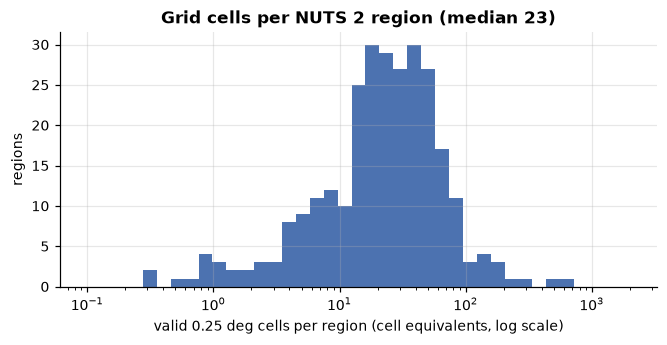

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
kept = coverage[coverage["kept"]]
ax.hist(kept["effective_cells"], bins=np.logspace(-1, 3.3, 40), color="#4c72b0")
ax.set_xscale("log")
ax.set_xlabel("valid 0.25 deg cells per region (cell equivalents, log scale)")
ax.set_ylabel("regions")
ax.set_title(f"Grid cells per NUTS 2 region (median {kept['effective_cells'].median():.0f})")
viz.save(fig, FIG, "02_cells_per_region")
kept.sort_values("effective_cells").head(6)

**Worked example.** To make the weighting rule concrete, the figure below follows one region, Luxembourg (LU00), on 15 July. Luxembourg touches 12 grid cells but contains only one of them completely. The fraction of each cell inside the region comes from the same `regionmask` function as in `RegionalAggregator`; multiplied by cos(latitude), it gives the cell's weight, and the weighted mean gives a single value for the region.

In [ ]:
# Worked example of the aggregation: Luxembourg (LU00) on 15 July of YEAR
import geopandas as gpd
import matplotlib.colors as mcolors
import regionmask
from shapely.geometry import box

example_id, example_day = "LU00", f"{YEAR}-07-15"
west, south, east, north = 5.5, 49.25, 6.75, 50.25

region = regions.loc[regions["region_id"] == example_id, "geometry"].iloc[0]
window = grid["tg"].sel(time=example_day, lon=slice(west, east), lat=slice(south, north)).compute()
# same function as RegionalAggregator: fraction of each cell inside the region
frac = regionmask.Regions([region], abbrevs=[example_id], names=[example_id], overlap=False) \
    .mask_3D_frac_approx(window["lon"], window["lat"]).isel(region=0)

half = 0.125  # half a 0.25 deg cell
cells = []
for la in window["lat"].values:
    for lo in window["lon"].values:
        f = float(frac.sel(lat=la, lon=lo).fillna(0))
        cells.append((lo, la, f, float(window.sel(lat=la, lon=lo)), box(lo - half, la - half, lo + half, la + half)))
used = [c for c in cells if c[2] > 0]
weights = [c[2] * np.cos(np.deg2rad(c[1])) for c in used]
value = sum(w * c[3] for w, c in zip(weights, used)) / sum(weights)
n_full = sum(c[2] >= 0.995 for c in used)
print(f"{example_id}: {len(used)} cells touch the region ({n_full} fully inside), weighted mean tg = {value:.1f} deg C")

ink, accent = "#1E2230", "#B23A0E"
neighbours = regions[regions.intersects(box(west, south, east, north)) & (regions["region_id"] != example_id)]
outline = gpd.GeoSeries([region])
with plt.rc_context({"axes.grid": False, "font.size": 12}):
    fig = plt.figure(figsize=(17, 7), facecolor="white")
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.95], wspace=0.08)
    panels = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])]
    oranges, blues = plt.get_cmap("Oranges"), plt.get_cmap("Blues")
    norm = mcolors.Normalize(14, 28)
    for ax, mode in zip(panels[:2], ["temp", "share"]):
        neighbours.boundary.plot(ax=ax, color="#B8B2A6", linewidth=0.8)
        for lo, la, f, t, b in cells:
            x, y = b.exterior.xy
            if mode == "temp":
                ax.fill(x, y, color=oranges(0.15 + 0.45 * norm(t)) if f > 0 else "#F3F0EA", ec="white", lw=1.5)
                ax.text(lo, la, f"{t:.1f}°", ha="center", va="center", fontsize=14 if f > 0 else 11,
                        color=ink if f > 0 else "#6B6F7B", fontweight="bold" if f > 0 else "normal")
            else:
                ax.fill(x, y, color=blues(0.12 + 0.75 * f) if f > 0 else "#FAF7F2", ec="white", lw=1.5)
                if f > 0:
                    ax.text(lo, la, f"{100 * f:.0f} %", ha="center", va="center", fontsize=14,
                            color="white" if f >= 0.6 else ink, fontweight="bold")
        outline.boundary.plot(ax=ax, color=ink, linewidth=3)
        ax.set_xlim(west, east); ax.set_ylim(south, north)
        ax.set_aspect(1 / np.cos(np.deg2rad(49.75)))
        ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
        for spine in ax.spines.values():
            spine.set_visible(False)
    panels[0].text(0, -0.05, f"Each square = one value (tg, {example_day}).\nBlack line = the region {example_id} (Luxembourg).",
                   transform=panels[0].transAxes, fontsize=14, color=ink, va="top")
    panels[1].text(0, -0.05, f"{n_full} cell fully inside (100 %), {len(used) - n_full} partly inside.\nweight = share × cos(latitude)",
                   transform=panels[1].transAxes, fontsize=14, color=ink, va="top")
    panels[2].axis("off")
    fig.canvas.draw()
    top = panels[0].get_position()
    for ax, title in zip(panels, ["1 · E-OBS cells on the region", "2 · Share of each cell", "3 · One value for the region"]):
        fig.text(ax.get_position().x0, top.y1 + 0.03, title, fontsize=17, fontweight="bold", color=ink)
    rows = sorted(zip(used, weights), key=lambda z: -z[1])
    table = ["share   weight    tg"] + [f"{100 * c[2]:4.0f} %   {w:.2f}   {c[3]:5.1f}°" for c, w in rows]
    x3 = panels[2].get_position().x0
    fig.text(x3, top.y1, "\n".join(table), fontsize=13, family="DejaVu Sans Mono", color=ink, va="top", linespacing=1.3)
    fig.text(x3, top.y0 - 0.05, "Σ(weight × tg) / Σ(weight)", fontsize=15, color=ink)
    fig.text(x3, top.y0 - 0.13, f"= {value:.1f} °C for {example_id} on {example_day}", fontsize=17, fontweight="bold", color=accent)
    viz.save(fig, FIG, "02b_aggregation_example_luxembourg")

**Indicators** (`IndicatorCalculator`). Fixed thresholds such as 30 °C, 35 °C, or 20 °C for tropical nights, are easy to interpret, but they do not mean the same thing in Finland and in Andalusia. We therefore also use relative indicators (days above the local 90th percentile, heatwaves), which can be compared across Europe.

**Drought index** (`processing/drought.py`). We compute the climatic water balance D = P − PET, where the potential evapotranspiration (PET) is estimated with the Thornthwaite formula from monthly temperature, latitude and day length. The balance is summed over three months, fitted month by month with a log-logistic distribution on 1991-2020 (probability-weighted moments, Vicente-Serrano et al., 2010) and converted to a standard normal value. The August value covers June to August, so we use it as the summer drought index. Because Thornthwaite ignores radiation, wind and humidity, we call it a *SPEI-like* index.

In [8]:
from climate_europe.processing.indicators import IndicatorCalculator

calculator = IndicatorCalculator(cfg)
indicators = calculator.compute_all(daily, latitudes=regions.set_index("region_id")["latitude"])
indicators = indicators[indicators["region_id"].isin(regions["region_id"])].reset_index(drop=True)
indicators.to_parquet(INTERIM / "indicators.parquet", index=False)
print(indicators.shape)
indicators[indicators["year"] == YEAR].head()

19:19:50 | processing.indicators | INFO | 8 region-years with low summer coverage set to NaN


(13207, 21)


,region_id,year,coverage,drought_index,heatwave_count,heatwave_days,heatwave_intensity,heatwave_max_length,hot_days_30,hot_days_35,hot_days_p90,max_consecutive_dry_days,summer_rr,summer_rr_anomaly,summer_tg,summer_tg_anomaly,summer_tn,summer_tn_anomaly,summer_tx,summer_tx_anomaly,tropical_nights
46,AL01,2026,1.0,-1.54,4.0,38.0,1.88,16.0,51.0,1.0,41.0,35.0,76.48,-25.95,22.68,2.33,15.31,1.54,29.93,3.28,0.0
93,AL02,2026,1.0,-1.90,4.0,45.0,2.12,18.0,71.0,11.0,45.0,35.0,45.32,-27.55,24.06,2.33,16.40,1.80,31.95,3.91,2.0
140,AL03,2026,1.0,-0.83,5.0,38.0,2.22,18.0,63.0,9.0,42.0,20.0,62.72,-3.91,23.13,1.33,15.90,1.34,31.15,3.51,0.0
187,AT11,2026,1.0,-2.43,4.0,23.0,3.24,9.0,44.0,12.0,28.0,18.0,117.85,-51.37,22.90,2.58,16.25,1.69,29.56,3.42,8.0
234,AT12,2026,1.0,-2.27,5.0,23.0,3.56,8.0,31.0,8.0,30.0,16.0,141.77,-49.39,21.36,2.66,14.77,1.73,27.91,3.58,4.0


## 2.2 Cleaning
We check missing values, the coverage of each region and outliers.

In [9]:
print("Missing daily values per variable:")
print(daily[["tg", "tn", "tx", "rr"]].isna().sum().to_string())
inconsistent = ((daily["tn"] > daily["tg"] + 0.05) | (daily["tg"] > daily["tx"] + 0.05)).mean()
print(f"\nDays with tn > tg or tg > tx: {inconsistent:.4%}   negative rr: {(daily['rr'] < 0).sum()}")
low = indicators[indicators["coverage"] < cfg["aggregation"]["min_summer_coverage"]]
print(f"\nRegion-summers with < {cfg['aggregation']['min_summer_coverage']:.0%} valid days (indicators set to NaN):")
low[["region_id", "year", "coverage"]]

Missing daily values per variable:
tg     34
tn     33
tx     14
rr    664

Days with tn > tg or tg > tx: 0.0430%   negative rr: 0

Region-summers with < 90% valid days (indicators set to NaN):


,region_id,year,coverage
7681,IS00,2000,0.66
7685,IS00,2004,0.34
7688,IS00,2007,0.66
7695,IS00,2014,0.66
7696,IS00,2015,0.67
7700,IS00,2019,0.67
7701,IS00,2020,0.66
7707,IS00,2026,0.33


The daily table is almost complete. Nearly all missing values concern precipitation in Iceland, where E-OBS has few stations (especially in the 2026 update); elsewhere, only a few isolated days are missing. The expected order tn ≤ tg ≤ tx holds everywhere apart from tiny rounding differences, and there is no negative precipitation. Only a handful of region-summers have less than 90 % of valid days, mostly in Iceland (including 2026). We set them to missing rather than filling them in.

**Outliers.** Each indicator is standardised within its region, and the values beyond 4 standard deviations are listed below. They all match well-known events (2003 in France, 2010 in eastern Europe, 2022, 2026), so we keep them: in a study of heat extremes, these values are precisely what we are looking for.

174 region-years with |z| > 4 on at least one indicator; most frequent years:
year
2026    89
2024    28
1994     8
2018     8
2003     7
2010     7


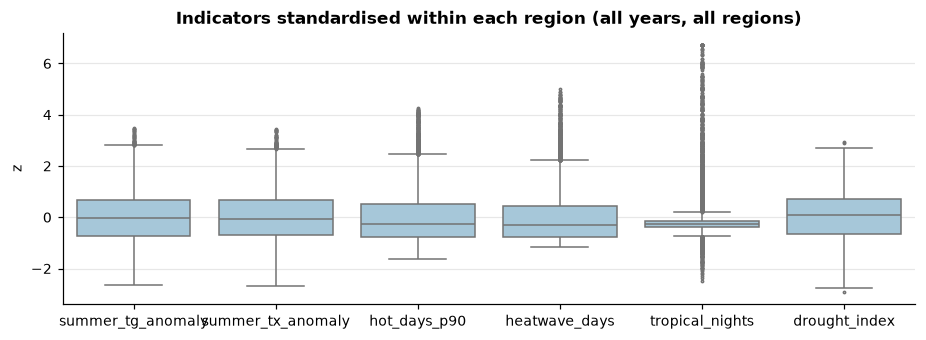

In [10]:
cols = ["summer_tg_anomaly", "summer_tx_anomaly", "hot_days_p90", "heatwave_days", "tropical_nights", "drought_index"]
z_within = indicators.groupby("region_id")[cols].transform(lambda s: (s - s.mean()) / s.std())
extreme = indicators.loc[(z_within.abs() > 4).any(axis=1), ["region_id", "year"]]
print(f"{len(extreme)} region-years with |z| > 4 on at least one indicator; most frequent years:")
print(extreme["year"].value_counts().head(6).to_string())

fig, ax = plt.subplots(figsize=(10, 3.2))
sns.boxplot(data=z_within.melt(var_name="indicator", value_name="z"), x="indicator", y="z", ax=ax,
            fliersize=1.5, color="#9ecae1")
ax.set_title("Indicators standardised within each region (all years, all regions)")
ax.set_xlabel("")
viz.save(fig, FIG, "03_outliers")

## 2.3 Univariate and bivariate analysis

**Europe-wide series.** To summarise Europe with one value per year, we average the regions weighted by their area. A simple mean would give too much weight to the many small regions of the Benelux and Germany.

In [11]:
area = regions.set_index("region_id")["area_km2"]


def europe_mean(table, columns):
    """Area-weighted mean over regions, per year (missing regions are ignored)."""
    def weighted(group):
        weights = group["region_id"].map(area)
        return pd.Series({c: np.average(group[c].dropna(), weights=weights[group[c].notna()]) for c in columns})
    return table.groupby("year").apply(weighted, include_groups=False)


series_cols = ["summer_tg_anomaly", "summer_tx_anomaly", "summer_tn_anomaly", "hot_days_p90", "heatwave_days",
               "tropical_nights", "summer_rr_anomaly", "drought_index", "max_consecutive_dry_days"]
europe = europe_mean(indicators, series_cols)
europe.tail(8)

,summer_tg_anomaly,summer_tx_anomaly,summer_tn_anomaly,hot_days_p90,heatwave_days,tropical_nights,summer_rr_anomaly,drought_index,max_consecutive_dry_days
year,,,,,,,,,
2019,0.98,1.17,0.56,12.82,8.08,3.73,-9.46,-0.77,22.60
2020,0.50,0.53,0.20,10.94,6.70,3.48,3.47,-0.10,21.28
2021,0.82,0.84,0.59,15.08,11.49,4.22,7.24,-0.20,21.77
2022,1.51,1.81,0.92,18.96,13.40,4.60,-11.09,-1.12,23.36
2023,1.03,1.09,0.78,15.82,10.88,5.54,22.50,-0.07,25.80
2024,1.64,1.71,1.36,18.29,12.19,7.66,-4.66,-0.86,19.55
2025,1.19,1.62,0.75,20.74,15.55,5.90,-21.51,-1.13,25.48
2026,1.58,2.10,1.23,23.12,18.61,7.62,-20.50,-1.20,24.93


2026 rank since 1980 (1 = highest): tg anomaly 2, hot days p90 1, heatwave days 1, tropical nights 2; SPEI rank from the driest: 2
Warmest summers: {2024: 1.64, 2026: 1.58, 2022: 1.51, 2025: 1.19, 2003: 1.18}


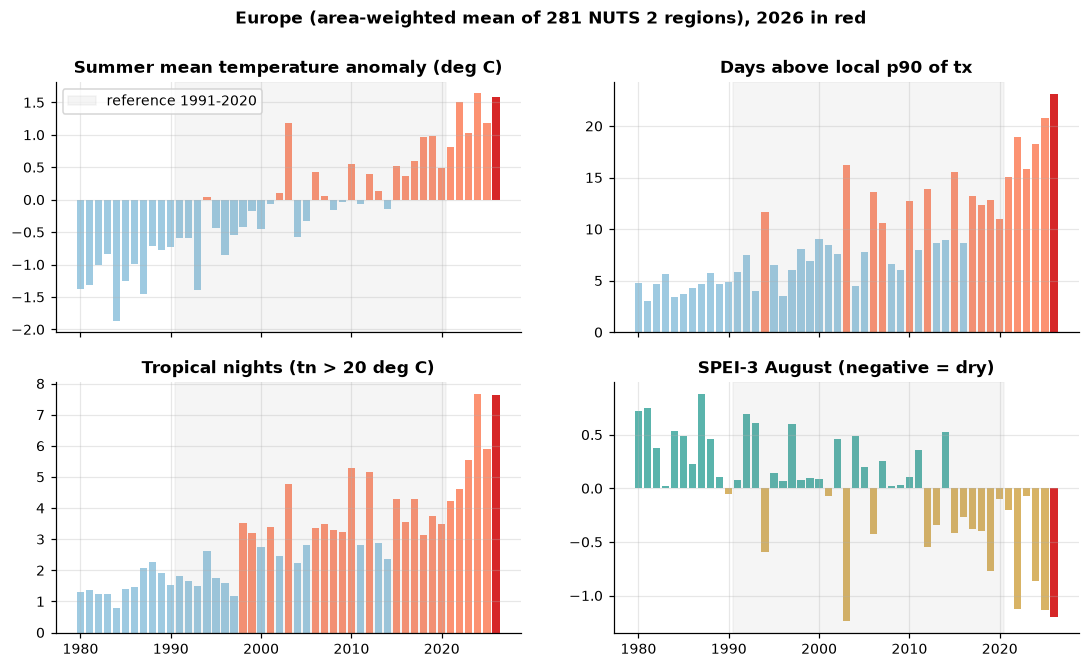

In [12]:
panels = [("summer_tg_anomaly", "Summer mean temperature anomaly (deg C)"), ("hot_days_p90", "Days above local p90 of tx"),
          ("tropical_nights", "Tropical nights (tn > 20 deg C)"), ("drought_index", "SPEI-3 August (negative = dry)")]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, (col, title) in zip(axes.ravel(), panels):
    colors = np.where(europe.index == YEAR, "#d62728", np.where(europe[col] > europe.loc[REF[0]:REF[1], col].mean(), "#fc9272", "#9ecae1"))
    if col == "drought_index":
        colors = np.where(europe.index == YEAR, "#d62728", np.where(europe[col] < 0, "#d8b365", "#5ab4ac"))
    ax.bar(europe.index, europe[col], color=colors)
    ax.axvspan(REF[0] - 0.5, REF[1] + 0.5, color="grey", alpha=0.08, label="reference 1991-2020")
    ax.set_title(title)
axes[0, 0].legend(loc="upper left")
fig.suptitle(f"Europe (area-weighted mean of {len(regions)} NUTS 2 regions), {YEAR} in red", fontweight="bold")
viz.save(fig, FIG, "04_europe_series")
rank = europe.rank(ascending=False).loc[YEAR]
print(f"{YEAR} rank since 1980 (1 = highest): tg anomaly {rank['summer_tg_anomaly']:.0f}, hot days p90 {rank['hot_days_p90']:.0f}, "
      f"heatwave days {rank['heatwave_days']:.0f}, tropical nights {rank['tropical_nights']:.0f}; "
      f"SPEI rank from the driest: {europe['drought_index'].rank().loc[YEAR]:.0f}")
print("Warmest summers:", europe["summer_tg_anomaly"].nlargest(5).round(2).to_dict())

**Distribution shift.** Each curve shows the distribution of the regional summer temperature anomalies over one period. The whole distribution moves to the right from one decade to the next, and 2026 lies at the far end, with most regions more than 2 °C above normal.

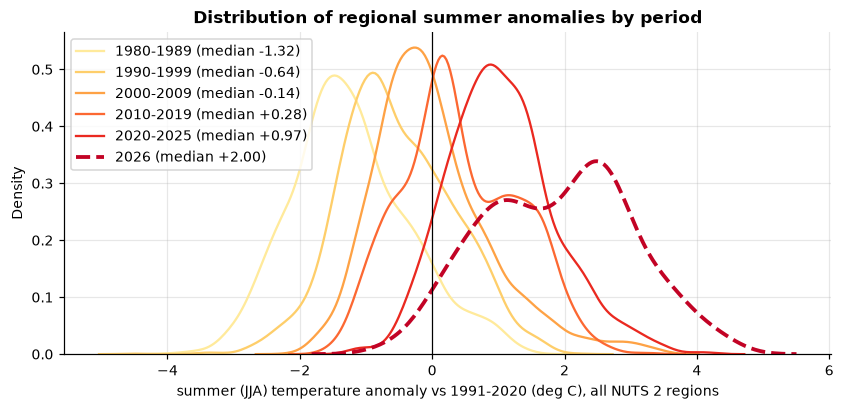

In [13]:
periods = {"1980-1989": (1980, 1989), "1990-1999": (1990, 1999), "2000-2009": (2000, 2009), "2010-2019": (2010, 2019),
           "2020-2025": (2020, 2025), str(YEAR): (YEAR, YEAR)}
fig, ax = plt.subplots(figsize=(9, 3.8))
palette = sns.color_palette("YlOrRd", len(periods))
for (label, (a, b)), color in zip(periods.items(), palette):
    values = indicators.loc[indicators["year"].between(a, b), "summer_tg_anomaly"].dropna()
    sns.kdeplot(values, ax=ax, label=f"{label} (median {values.median():+.2f})", color=color,
                linewidth=2.5 if label == str(YEAR) else 1.5, linestyle="--" if label == str(YEAR) else "-")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("summer (JJA) temperature anomaly vs 1991-2020 (deg C), all NUTS 2 regions")
ax.set_title("Distribution of regional summer anomalies by period")
ax.legend()
viz.save(fig, FIG, "05_distribution_shift")

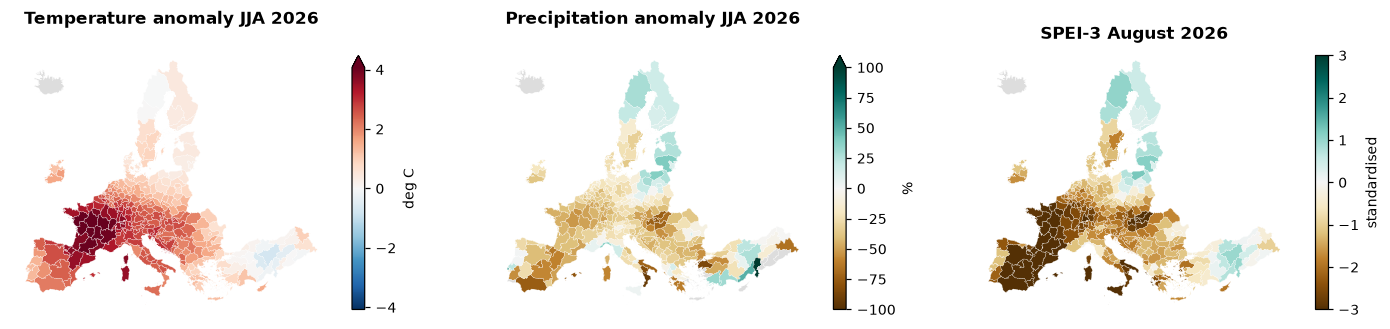

In [14]:
shapes = viz.map_layer(regions)
year_ind = indicators[indicators["year"] == YEAR].set_index("region_id")
shapes = shapes.join(year_ind[["summer_tg_anomaly", "summer_rr_anomaly", "drought_index", "heatwave_days"]], on="region_id")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
viz.plot_map(shapes, "summer_tg_anomaly", axes[0], cmap="RdBu_r", center=0, title=f"Temperature anomaly JJA {YEAR}", label="deg C")
viz.plot_map(shapes, "summer_rr_anomaly", axes[1], cmap="BrBG", vmin=-100, vmax=100, title=f"Precipitation anomaly JJA {YEAR}", label="%")
viz.plot_map(shapes, "drought_index", axes[2], cmap="BrBG", vmin=-3, vmax=3, title=f"SPEI-3 August {YEAR}", label="standardised")
viz.save(fig, FIG, "06_maps_2026")

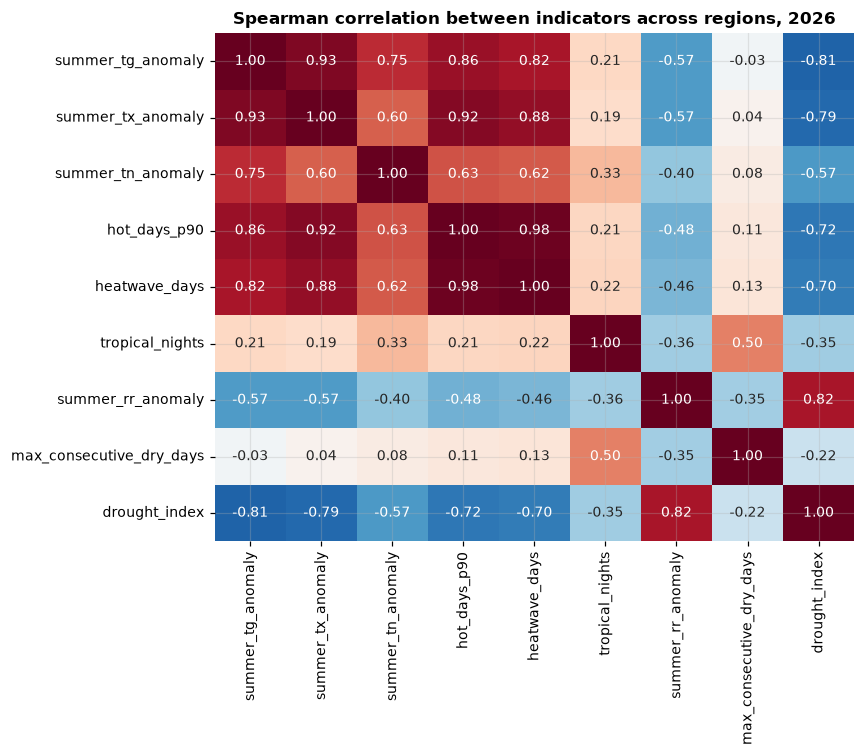

In [15]:
corr_cols = ["summer_tg_anomaly", "summer_tx_anomaly", "summer_tn_anomaly", "hot_days_p90", "heatwave_days", "tropical_nights",
             "summer_rr_anomaly", "max_consecutive_dry_days", "drought_index"]
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(year_ind[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=False)
ax.set_title(f"Spearman correlation between indicators across regions, {YEAR}")
viz.save(fig, FIG, "07_correlation_2026")

Part of the link between SPEI and temperature is built into the index, since temperature enters the PET. The right panel therefore uses precipitation alone, which does not depend on temperature: the hottest regions were still the driest ones.

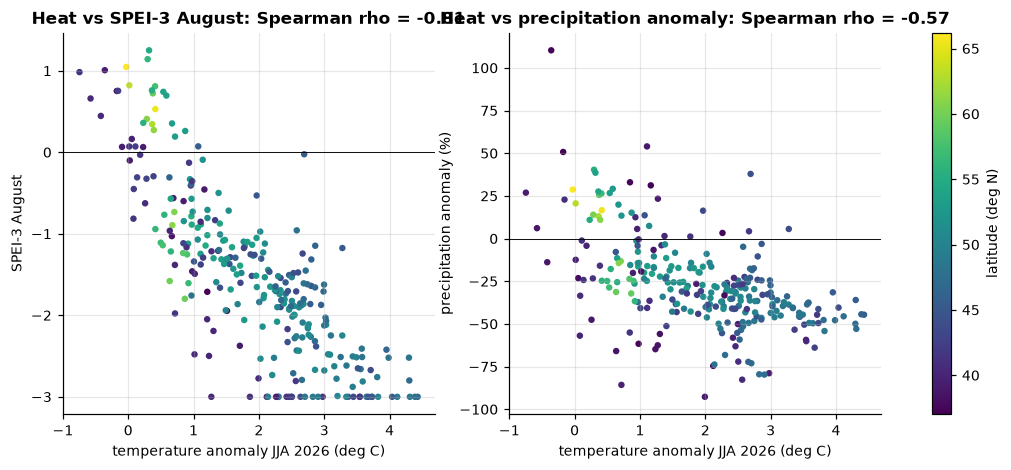

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in [(axes[0], "drought_index", "SPEI-3 August"), (axes[1], "summer_rr_anomaly", "precipitation anomaly (%)")]:
    sc = ax.scatter(year_ind["summer_tg_anomaly"], year_ind[col], c=regions.set_index("region_id").loc[year_ind.index, "latitude"],
                    cmap="viridis", s=18, edgecolor="none")
    rho = year_ind[["summer_tg_anomaly", col]].corr(method="spearman").iloc[0, 1]
    ax.set_xlabel(f"temperature anomaly JJA {YEAR} (deg C)"); ax.set_ylabel(label)
    ax.set_title(f"Heat vs {label.split(' (')[0]}: Spearman rho = {rho:.2f}")
    ax.axhline(0, color="black", linewidth=0.6)
fig.colorbar(sc, ax=axes, label="latitude (deg N)")
viz.save(fig, FIG, "08_heat_vs_dry_2026")

## 2.4 Statistical tests and intermediate conclusions
We now test the trends and measure how unusual 2026 was. Each result leads to one of the research questions.

* **Trend test.** Mann-Kendall test (non-parametric, robust to outliers, no normality assumption) with Sen's slope, computed on **1980-2025** so that 2026 can then be compared with the trend. Since we run 281 tests at once, about 14 of them would come out "significant" at the 5 % level by chance alone, so we apply the Benjamini-Hochberg false discovery rate correction (`significant_fdr`).
* **Z-score of 2026.** (value in 2026 − mean 1991-2020) / standard deviation 1991-2020, together with the rank of 2026 among the 47 summers.
* **Departure from the trend.** Observed 2026 value minus the value predicted by the Sen trend line, divided by the standard deviation of the detrended series. This separates a summer that is warm *because* the climate is warming from one that is warm *beyond* the trend.

In [17]:
from climate_europe.analysis import stats

trend_vars = ["summer_tg_anomaly", "summer_tx_anomaly", "summer_tn_anomaly", "hot_days_p90", "heatwave_days", "tropical_nights",
              "summer_rr_anomaly", "max_consecutive_dry_days", "drought_index"]
trends = {v: stats.trend_table(indicators, v, years=TREND) for v in trend_vars}
pd.DataFrame(
    {
        v: {
            "median slope / decade": t["slope_decade"].median(),
            "share significant increase (FDR)": ((t["slope"] > 0) & t["significant_fdr"]).mean(),
            "share significant decrease (FDR)": ((t["slope"] < 0) & t["significant_fdr"]).mean(),
        }
        for v, t in trends.items()
    }
).T

,median slope / decade,share significant increase (FDR),share significant decrease (FDR)
summer_tg_anomaly,0.57,9.75e-01,0.00e+00
summer_tx_anomaly,0.72,9.50e-01,0.00e+00
summer_tn_anomaly,0.42,8.90e-01,7.12e-03
hot_days_p90,2.50,8.65e-01,0.00e+00
heatwave_days,1.25,7.47e-01,0.00e+00
tropical_nights,0.00,1.74e-01,0.00e+00
summer_rr_anomaly,0.25,3.56e-03,0.00e+00
max_consecutive_dry_days,0.00,0.00e+00,0.00e+00
drought_index,-0.19,0.00e+00,1.96e-01


In [18]:
# Mann-Kendall assumes independent years: check the lag-1 autocorrelation of the detrended series
tg_trend = trends["summer_tg_anomaly"]
detrended = indicators[indicators["year"].between(*TREND)].merge(tg_trend[["region_id", "slope", "intercept"]], on="region_id")
detrended["residual"] = detrended["summer_tg_anomaly"] - detrended["intercept"] - detrended["slope"] * detrended["year"]
lag1 = detrended.groupby("region_id")["residual"].apply(lambda s: s.autocorr(1))
print(f"Lag-1 autocorrelation of detrended summer temperature: median {lag1.median():.2f}, "
      f"share > 0.3: {(lag1 > 0.3).mean():.1%} -> the independence assumption is acceptable")

europe_trend = stats.trend_mann_kendall(europe.loc[TREND[0]:TREND[1], "summer_tg_anomaly"])
print(f"Europe-wide: {10 * europe_trend['slope']:+.2f} deg C/decade, p = {europe_trend['p_value']:.1e}")
tg_trend["slope_decade"].describe()

Lag-1 autocorrelation of detrended summer temperature: median -0.02, share > 0.3: 2.8% -> the independence assumption is acceptable
Europe-wide: +0.56 deg C/decade, p = 8.6e-14


count    281.00
mean       0.58
std        0.19
min        0.13
25%        0.48
50%        0.57
75%        0.69
max        1.59
Name: slope_decade, dtype: float64

In [19]:
z2026 = stats.anomaly_zscore(indicators, "summer_tg_anomaly", YEAR, REF)
print(f"{YEAR}: median z = {z2026['zscore'].median():.2f}; z > 2 in {(z2026['zscore'] > 2).sum()} of {len(z2026)} regions; "
      f"record summer in {z2026['is_record'].sum()} regions")
z2026.merge(regions[["region_id", "name", "country"]]).nlargest(10, "zscore")[["region_id", "name", "country", "value", "zscore", "rank"]]

2026: median z = 2.20; z > 2 in 150 of 280 regions; record summer in 111 regions


,region_id,name,country,value,zscore,rank
138,FRH0,Bretagne,FR,3.44,4.85,1
141,FRI3,Poitou-Charentes,FR,4.39,4.82,1
106,ES12,Principado de Asturias,ES,2.88,4.79,1
137,FRG0,Pays de la Loire,FR,4.12,4.68,1
130,FRD1,Basse-Normandie,FR,3.34,4.55,1
127,FRB0,Centre — Val de Loire,FR,4.31,4.52,1
139,FRI1,Aquitaine,FR,3.73,4.50,1
108,ES21,País Vasco,ES,3.51,4.50,1
140,FRI2,Limousin,FR,4.43,4.39,1
143,FRJ2,Midi-Pyrénées,FR,4.04,4.16,1


In [20]:
departure = stats.departure_from_trend(indicators, tg_trend, "summer_tg_anomaly", YEAR)
by_country = departure.merge(regions[["region_id", "country"]]).groupby("country")["residual_z"].median().sort_values()

expected = europe_trend["intercept"] + europe_trend["slope"] * YEAR
resid_sd = (europe.loc[TREND[0]:TREND[1], "summer_tg_anomaly"]
            - (europe_trend["intercept"] + europe_trend["slope"] * europe.loc[TREND[0]:TREND[1]].index)).std(ddof=2)
observed = europe.loc[YEAR, "summer_tg_anomaly"]
print(f"Europe: observed {observed:+.2f} deg C, expected from trend {expected:+.2f} deg C, "
      f"departure {observed - expected:+.2f} deg C = {(observed - expected) / resid_sd:+.2f} sd")
print(f"Regions above trend by > 2 sd: {(departure['residual_z'] > 2).sum()}, below by > 2 sd: {(departure['residual_z'] < -2).sum()}")
print("Median departure (sd) by country, lowest and highest:")
print(pd.concat([by_country.head(4), by_country.tail(5)]).round(2).to_string())

Europe: observed +1.58 deg C, expected from trend +1.16 deg C, departure +0.42 deg C = +1.11 sd
Regions above trend by > 2 sd: 63, below by > 2 sd: 16
Median departure (sd) by country, lowest and highest:
country
TR   -2.13
LT   -0.94
PL   -0.71
FI   -0.58
ES    2.33
LI    2.70
CH    2.87
FR    3.16
IS     NaN


In [21]:
north_south = stats.north_south_comparison(tg_trend, regions, cfg["analysis"]["latitude_bands"])
print("Kruskal-Wallis across bands:", {k: f"{v:.2g}" for k, v in north_south.attrs["kruskal"].items()})
print("Spearman slope vs latitude:", {k: f"{v:.2g}" for k, v in north_south.attrs["spearman"].items()})
north_south

Kruskal-Wallis across bands: {'H': '38', 'p_value': '5.8e-09'}
Spearman slope vs latitude: {'rho': '-0.33', 'p_value': '1.5e-08', 'n': '2.8e+02'}


,band,n_regions,mean_slope_decade,median_slope_decade,share_significant
0,30-45N,104,0.62,0.63,0.97
1,45-55N,155,0.58,0.58,0.99
2,55-72N,22,0.36,0.37,0.86


In [22]:
spei_trend = trends["drought_index"]
rr_trend = trends["summer_rr_anomaly"]
print(f"SPEI-3 August: significant drying in {((spei_trend['slope'] < 0) & spei_trend['significant_fdr']).mean():.0%} of regions, "
      f"significant wetting in {((spei_trend['slope'] > 0) & spei_trend['significant_fdr']).mean():.0%}")
print(f"Summer precipitation: significant change in {rr_trend['significant_fdr'].mean():.0%} of regions")

SPEI-3 August: significant drying in 20% of regions, significant wetting in 0%
Summer precipitation: significant change in 0% of regions


**Intermediate conclusions and research questions**
1. Summer temperature rises significantly in almost every region, by about +0.57 °C per decade (median), and maximum temperatures rise faster than minimum temperatures. The number of days above the local 90th percentile increases as well. How large and how uniform is this warming? (**Q1**)
2. In 2026, the Europe-wide anomaly is one of the two highest since 1980. More than half of the regions are beyond 2 standard deviations, and about 110 of them had their warmest summer on record, mainly in France and northern Spain. How exceptional was 2026, and where? (**Q2**)
3. Compared with the trend line, 2026 is only moderately above expectations at European scale, but far above them in western Europe, while the east (Turkey, the Baltic states, Poland) stayed below its trend. Is 2026 an exception or the continuation of the trend? (**Q3**)
4. Warming is weaker in the north (55-72°N) than in the south and the centre. The Kruskal-Wallis and Spearman tests are significant, although their p-values are optimistic because neighbouring regions are correlated. Is there a north-south gradient? (**Q4**)
5. In 2026, heat and drought went together, even when drought is measured with precipitation alone. SPEI shows a significant drying trend in about a fifth of the regions, while summer rainfall itself has no significant trend: the drying comes from a higher evaporative demand. Which regions share the same heat and drought profile? (**Q5**)

## 2.5 Research questions
- **Q1. Trend.** How fast have European summers warmed since 1980 at NUTS 2 level, and is the warming significant everywhere?
- **Q2. The 2026 anomaly.** How exceptional was summer 2026 compared with the 1991-2020 normal, and where did it set records?
- **Q3. Exception or continuation?** Is summer 2026 consistent with the long-term trend plus normal year-to-year variability, or does it go beyond it?
- **Q4. Geography.** Does the warming rate differ between southern, central and northern Europe?
- **Q5. Profiles.** Which regions share comparable heat and drought profiles in 2026, and do heat and drought occur together?

# 3. Clustering of NUTS 2 regions

## 3.1 Features, scaling and PCA
Each region is described by one row. We chose features that describe **summer 2026 and its long-term context**, that are easy to interpret and that are not redundant: the `tx` anomaly and `hot_days_p90` were left out because their correlation with the features we kept is above 0.8.

| Feature | Meaning |
|---|---|
| `tg_anomaly_2026` | heat intensity of summer 2026 (°C vs 1991-2020) |
| `heatwave_days_2026` | persistence of heat (days in heatwaves) |
| `tropical_nights_change_2026` | tropical nights in 2026 minus their 1991-2020 mean (night-time heat stress) |
| `spei3_aug_2026` | summer drought |
| `tg_trend_decade` | long-term warming rate 1980-2025 |

All features are standardised (mean 0, standard deviation 1) so that °C, days and SPEI values carry the same weight.

In [23]:
from climate_europe.analysis.clustering import ClusteringAnalysis

ref_nights = indicators[indicators["year"].between(*REF)].groupby("region_id")["tropical_nights"].mean()
features_table = pd.DataFrame(
    {
        "tg_anomaly_2026": year_ind["summer_tg_anomaly"],
        "heatwave_days_2026": year_ind["heatwave_days"],
        "tropical_nights_change_2026": year_ind["tropical_nights"] - ref_nights,
        "spei3_aug_2026": year_ind["drought_index"],
        "tg_trend_decade": tg_trend.set_index("region_id")["slope_decade"],
    }
).rename_axis("region_id")
features = list(features_table.columns)
clu = ClusteringAnalysis(cfg, features)
scaled = clu.prepare(features_table.reset_index())
pcs = clu.reduce(scaled, n_components=2)
print("Explained variance:", clu.pca_.explained_variance_ratio_.round(2), "total", clu.pca_.explained_variance_ratio_.sum().round(2))
clu.loadings()

19:20:01 | analysis.clustering | INFO | 1 regions dropped (missing feature): ['IS00']


Explained variance: [0.53 0.23] total 0.76


,pc1,pc2
tg_anomaly_2026,0.57,-0.09
heatwave_days_2026,0.54,0.03
tropical_nights_change_2026,0.22,0.65
spei3_aug_2026,-0.56,0.03
tg_trend_decade,-0.13,0.76


The first component is a "hot and dry 2026" axis: the temperature anomaly and the heatwave days on one side, SPEI on the other. The second component combines the increase in tropical nights and the long-term warming rate. Together they keep about three quarters of the variance, so the PCA plane gives a fair two-dimensional view of the clusters.

## 3.2 Choice of k (elbow, silhouette)

,k,inertia,silhouette,davies_bouldin
0,2,885.62,0.33,1.17
1,3,723.69,0.33,1.05
2,4,597.66,0.28,1.19
3,5,514.60,0.26,1.14
4,6,447.54,0.27,1.10
5,7,409.06,0.25,1.13
6,8,376.40,0.26,1.14
7,9,351.17,0.26,1.14
8,10,333.51,0.26,1.09


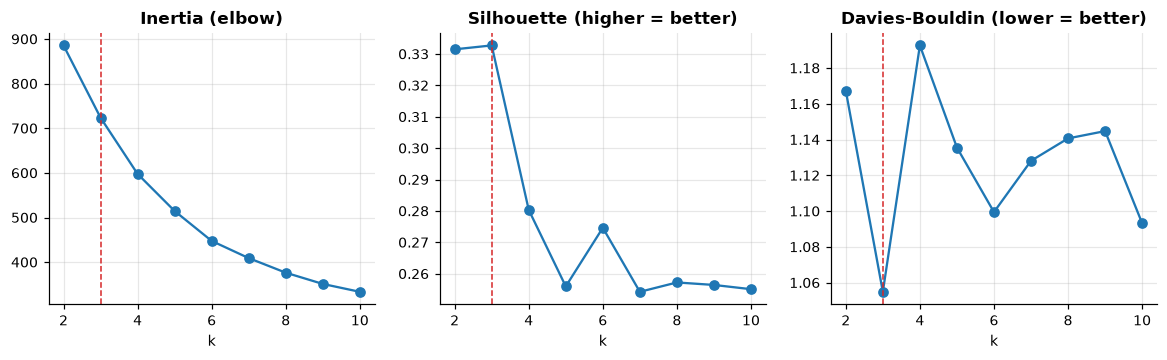

In [24]:
scores = clu.choose_k(scaled)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col, title in zip(axes, ["inertia", "silhouette", "davies_bouldin"],
                          ["Inertia (elbow)", "Silhouette (higher = better)", "Davies-Bouldin (lower = better)"]):
    ax.plot(scores["k"], scores[col], marker="o")
    ax.axvline(cfg["analysis"]["clustering"]["k"], color="#d62728", linestyle="--", linewidth=1)
    ax.set_title(title); ax.set_xlabel("k")
viz.save(fig, FIG, "09_choose_k")
scores

In [25]:
from sklearn.metrics import adjusted_rand_score

stability = {k: adjusted_rand_score(clu.fit(scaled, k), clu.fit(scaled, k, "hierarchical")) for k in range(2, 7)}
print("Agreement K-Means vs Ward (adjusted Rand index):", {k: round(v, 2) for k, v in stability.items()})
K = cfg["analysis"]["clustering"]["k"]

Agreement K-Means vs Ward (adjusted Rand index): {2: 0.78, 3: 0.81, 4: 0.6, 5: 0.41, 6: 0.46}


The elbow is not very clear, which is common when the data vary along continuous climate gradients. The silhouette is highest for k = 2 and 3 and drops at k = 4, and the Davies-Bouldin index is lowest at k = 3. K-Means and Ward's hierarchical clustering also agree well at k = 3 (ARI ≈ 0.8), and much less beyond. We therefore keep k = 3, the best compromise between separation, stability and interpretability. A silhouette of about 0.33 shows that the clusters exist but overlap: the European climate is a continuum, and the clusters should be read as types of regions rather than as sharp borders.

## 3.3 K-Means and hierarchical clustering

K-Means vs Ward at k = 3: ARI = 0.81
Ward       1   2    3
K-Means              
1        129   0    4
2          4  17    1
3          8   0  117


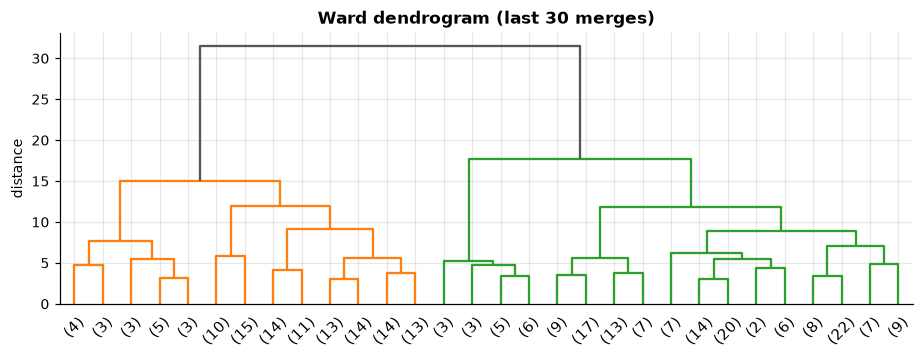

In [26]:
from scipy.cluster.hierarchy import dendrogram, linkage

labels = clu.fit(scaled, K, "kmeans")
labels_ward = clu.fit(scaled, K, "hierarchical")
print(f"K-Means vs Ward at k = {K}: ARI = {adjusted_rand_score(labels, labels_ward):.2f}")
print(pd.crosstab(labels.rename("K-Means"), labels_ward.rename("Ward")))

fig, ax = plt.subplots(figsize=(10, 3.2))
dendrogram(linkage(scaled, method="ward"), truncate_mode="lastp", p=30, ax=ax, color_threshold=None, above_threshold_color="#555555")
ax.set_title("Ward dendrogram (last 30 merges)"); ax.set_ylabel("distance")
viz.save(fig, FIG, "10_dendrogram")

## 3.4 Cluster profiles and interpretation
We describe each cluster by its average profile, then check whether the clusters form coherent areas on the map.

In [27]:
profile_table = features_table.join(regions.set_index("region_id")[["latitude"]]).join(
    year_ind[["summer_rr_anomaly", "max_consecutive_dry_days", "tropical_nights"]])
profiles = clu.profiles(profile_table, labels)
profiles

,n_regions,tg_anomaly_2026,heatwave_days_2026,tropical_nights_change_2026,spei3_aug_2026,tg_trend_decade,latitude,summer_rr_anomaly,max_consecutive_dry_days,tropical_nights
cluster,,,,,,,,,,
1,133,2.74,29.86,3.22,-2.14,0.56,46.88,-37.74,20.80,3.82
2,22,2.55,35.14,26.58,-2.46,0.59,41.18,-46.74,41.41,41.36
3,125,0.89,10.26,2.83,-0.68,0.60,48.15,-11.43,25.08,7.74


In [28]:
cluster_names = {
    1: "1 Western-central Europe: record heat and drought",
    2: "2 Mediterranean: hot nights, long dry spells",
    3: "3 North, east, Turkey, Atlantic fringe: moderate 2026",
}
# sanity check of the names against the profiles (labels are ordered by decreasing tg_anomaly_2026)
assert profiles.loc[2, "tropical_nights_change_2026"] == profiles["tropical_nights_change_2026"].max()
assert profiles.loc[3, "tg_anomaly_2026"] == profiles["tg_anomaly_2026"].min()
cluster_colors = {1: "#d7301f", 2: "#fdae61", 3: "#74add1"}

membership = labels.to_frame().join(regions.set_index("region_id")["country"])
print(membership.groupby("cluster")["country"].agg(lambda s: ", ".join(f"{c} {n}" for c, n in s.value_counts().items())).to_string())

cluster
1    DE 22, FR 21, BE 11, ES 11, AT 9, IT 9, CH 7, ...
2            IT 12, ES 5, CY 1, EL 1, FR 1, HR 1, HU 1
3    TR 26, PL 17, DE 16, EL 10, NL 8, SE 8, CZ 6, ...


In [29]:
# spatial autocorrelation: share of neighbouring region pairs that share a cluster, vs random labels
import geopandas as gpd

# "intersects" rather than "touches": GISCO borders have tiny gaps/overlaps at 1:1M
touch = gpd.sjoin(regions[["region_id", "geometry"]], regions[["region_id", "geometry"]], predicate="intersects")
pairs = touch[touch["region_id_left"] < touch["region_id_right"]][["region_id_left", "region_id_right"]]
pairs = pairs[pairs["region_id_left"].isin(labels.index) & pairs["region_id_right"].isin(labels.index)]
same = (labels.loc[pairs["region_id_left"]].values == labels.loc[pairs["region_id_right"]].values).mean()
rng = np.random.default_rng(cfg["analysis"]["clustering"]["random_state"])
random_same = np.mean([(lambda p: (p.loc[pairs["region_id_left"]].values == p.loc[pairs["region_id_right"]].values).mean())(
    pd.Series(rng.permutation(labels.values), index=labels.index)) for _ in range(200)])
print(f"{len(pairs)} neighbouring pairs: {same:.0%} in the same cluster vs {random_same:.0%} expected with random labels")

647 neighbouring pairs: 86% in the same cluster vs 43% expected with random labels


The clusters form coherent geographical areas, even though no coordinate was used as a feature: neighbouring regions share a cluster far more often than chance would predict. This suggests that the clusters capture real climate patterns. It is also a reminder that the 281 regions are not 281 independent observations, which makes the statistical tests of section 2.4 look more significant, and the silhouette better, than they really are.

# 4. Final data visualisation: answering the questions
Each question is answered with one figure. These figures are static; the interactive version of the results is the Power BI dashboard.

### Q1. How fast have European summers warmed since 1980, and is the warming significant everywhere?

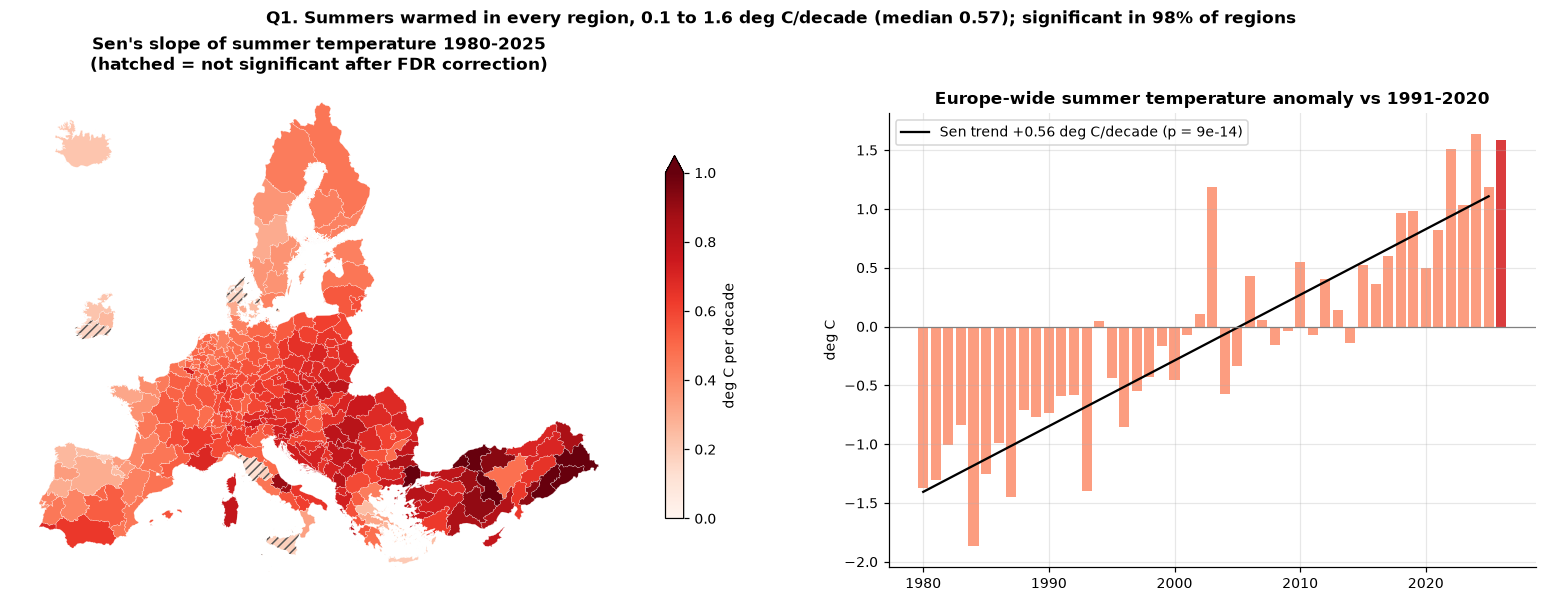

In [30]:
shapes = viz.map_layer(regions).join(tg_trend.set_index("region_id")[["slope_decade", "significant_fdr"]], on="region_id")
fig = plt.figure(figsize=(14, 5.5))
ax_map = fig.add_axes([0.0, 0.0, 0.5, 1.0])
viz.plot_map(shapes, "slope_decade", ax_map, cmap="Reds", vmin=0, vmax=1.0, label="deg C per decade",
             title="Sen's slope of summer temperature 1980-2025\n(hatched = not significant after FDR correction)",
             hatch_mask=~shapes["significant_fdr"].fillna(False).astype(bool))
ax_ts = fig.add_axes([0.57, 0.12, 0.42, 0.75])
years = europe.index.values
ax_ts.bar(years, europe["summer_tg_anomaly"], color=np.where(years == YEAR, "#d62728", "#fc9272"), alpha=0.9)
line_years = np.arange(TREND[0], TREND[1] + 1)
ax_ts.plot(line_years, europe_trend["intercept"] + europe_trend["slope"] * line_years, color="black",
           label=f"Sen trend {10 * europe_trend['slope']:+.2f} deg C/decade (p = {europe_trend['p_value']:.0e})")
ax_ts.axhline(0, color="grey", linewidth=0.8)
ax_ts.set_title("Europe-wide summer temperature anomaly vs 1991-2020"); ax_ts.set_ylabel("deg C"); ax_ts.legend(loc="upper left")
share = tg_trend["significant_fdr"].mean()
fig.suptitle(f"Q1. Summers warmed in every region, {tg_trend['slope_decade'].min():.1f} to {tg_trend['slope_decade'].max():.1f} deg C/decade "
             f"(median {tg_trend['slope_decade'].median():.2f}); significant in {share:.0%} of regions", fontweight="bold", y=1.04)
viz.save(fig, FIG, "Q1_trend")

### Q2. How exceptional was summer 2026, and where did it set records?

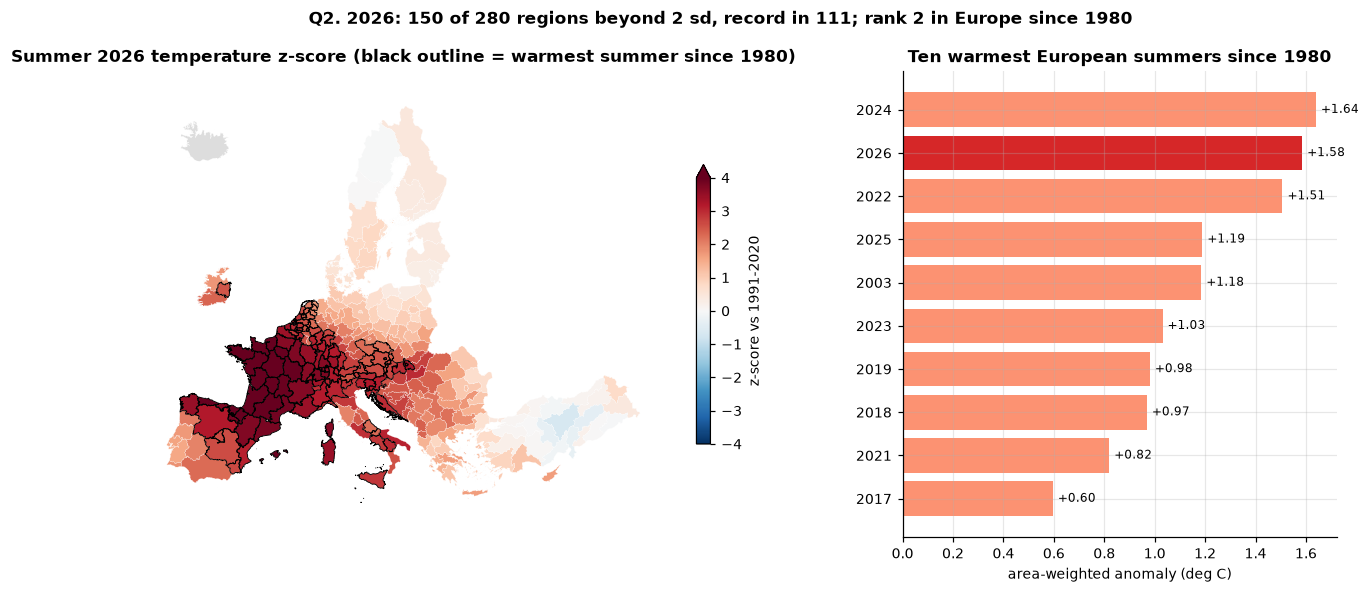

In [31]:
shapes = viz.map_layer(regions).join(z2026.set_index("region_id")[["zscore", "is_record"]], on="region_id")
fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
viz.plot_map(shapes, "zscore", ax_map, cmap="RdBu_r", vmin=-4, vmax=4, label="z-score vs 1991-2020",
             title=f"Summer {YEAR} temperature z-score (black outline = warmest summer since 1980)")
shapes[shapes["is_record"].fillna(False).astype(bool)].boundary.plot(ax=ax_map, color="black", linewidth=0.6)
top = europe["summer_tg_anomaly"].sort_values(ascending=False).head(10)[::-1]
ax_bar.barh(top.index.astype(str), top.values, color=["#d62728" if y == YEAR else "#fc9272" for y in top.index])
for y, v in enumerate(top.values):
    ax_bar.text(v + 0.02, y, f"{v:+.2f}", va="center", fontsize=8)
ax_bar.set_title("Ten warmest European summers since 1980"); ax_bar.set_xlabel("area-weighted anomaly (deg C)")
fig.suptitle(f"Q2. {YEAR}: {(z2026['zscore'] > 2).sum()} of {len(z2026)} regions beyond 2 sd, record in {z2026['is_record'].sum()}; "
             f"rank {int(rank['summer_tg_anomaly'])} in Europe since 1980", fontweight="bold")
viz.save(fig, FIG, "Q2_anomaly_2026")

### Q3. Is summer 2026 an exception or the continuation of the trend?

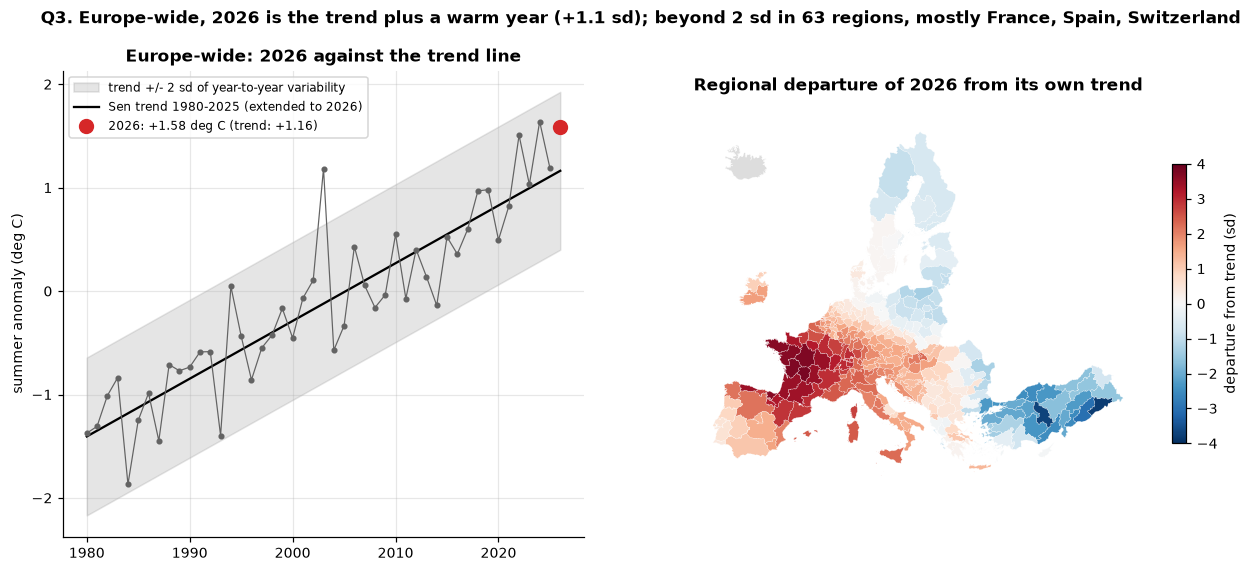

In [32]:
shapes = viz.map_layer(regions).join(departure.set_index("region_id")[["residual_z"]], on="region_id")
fig, (ax_ts, ax_map) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1.3]})
all_years = np.arange(TREND[0], YEAR + 1)
fit = europe_trend["intercept"] + europe_trend["slope"] * all_years
ax_ts.fill_between(all_years, fit - 2 * resid_sd, fit + 2 * resid_sd, color="grey", alpha=0.2, label="trend +/- 2 sd of year-to-year variability")
ax_ts.plot(all_years, fit, color="black", label="Sen trend 1980-2025 (extended to 2026)")
ax_ts.plot(europe.index[europe.index < YEAR], europe.loc[: YEAR - 1, "summer_tg_anomaly"], "o-", color="#636363", markersize=3, linewidth=0.8)
ax_ts.plot([YEAR], [observed], "o", color="#d62728", markersize=9, label=f"{YEAR}: {observed:+.2f} deg C (trend: {expected:+.2f})")
ax_ts.set_title("Europe-wide: 2026 against the trend line"); ax_ts.set_ylabel("summer anomaly (deg C)"); ax_ts.legend(loc="upper left", fontsize=8)
viz.plot_map(shapes, "residual_z", ax_map, cmap="RdBu_r", vmin=-4, vmax=4, label="departure from trend (sd)",
             title=f"Regional departure of {YEAR} from its own trend")
fig.suptitle(f"Q3. Europe-wide, {YEAR} is the trend plus a warm year ({(observed - expected) / resid_sd:+.1f} sd); "
             f"beyond 2 sd in {(departure['residual_z'] > 2).sum()} regions, mostly France, Spain, Switzerland", fontweight="bold")
viz.save(fig, FIG, "Q3_exception_or_trend")

### Q4. Does the warming rate differ between southern, central and northern Europe?

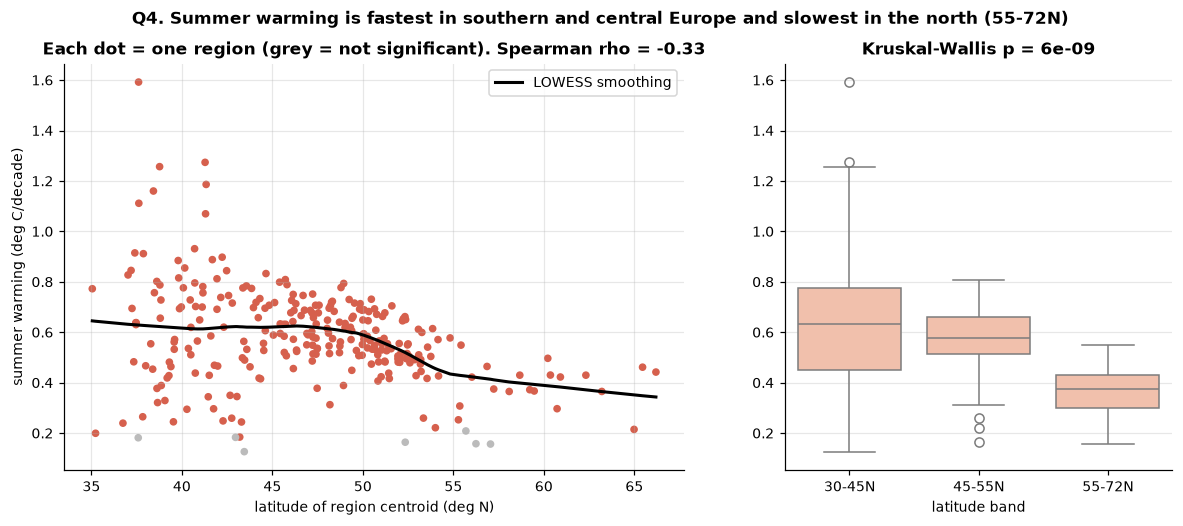

In [33]:
import statsmodels.api as sm

data = tg_trend.merge(regions[["region_id", "latitude"]], on="region_id")
data["band"] = pd.cut(data["latitude"], cfg["analysis"]["latitude_bands"], labels=north_south["band"].astype(str).tolist())
fig, (ax_sc, ax_box) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax_sc.scatter(data["latitude"], data["slope_decade"], c=np.where(data["significant_fdr"], "#d6604d", "#bbbbbb"), s=16)
lowess = sm.nonparametric.lowess(data["slope_decade"], data["latitude"], frac=0.4)
ax_sc.plot(lowess[:, 0], lowess[:, 1], color="black", linewidth=2, label="LOWESS smoothing")
ax_sc.set_xlabel("latitude of region centroid (deg N)"); ax_sc.set_ylabel("summer warming (deg C/decade)")
ax_sc.set_title(f"Each dot = one region (grey = not significant). Spearman rho = {north_south.attrs['spearman']['rho']:.2f}")
ax_sc.legend()
sns.boxplot(data=data, x="band", y="slope_decade", ax=ax_box, color="#fcbba1")
ax_box.set_xlabel("latitude band"); ax_box.set_ylabel("")
ax_box.set_title(f"Kruskal-Wallis p = {north_south.attrs['kruskal']['p_value']:.0e}")
fig.suptitle("Q4. Summer warming is fastest in southern and central Europe and slowest in the north (55-72N)", fontweight="bold")
viz.save(fig, FIG, "Q4_latitude")

### Q5. Which regions share comparable heat and drought profiles in 2026?

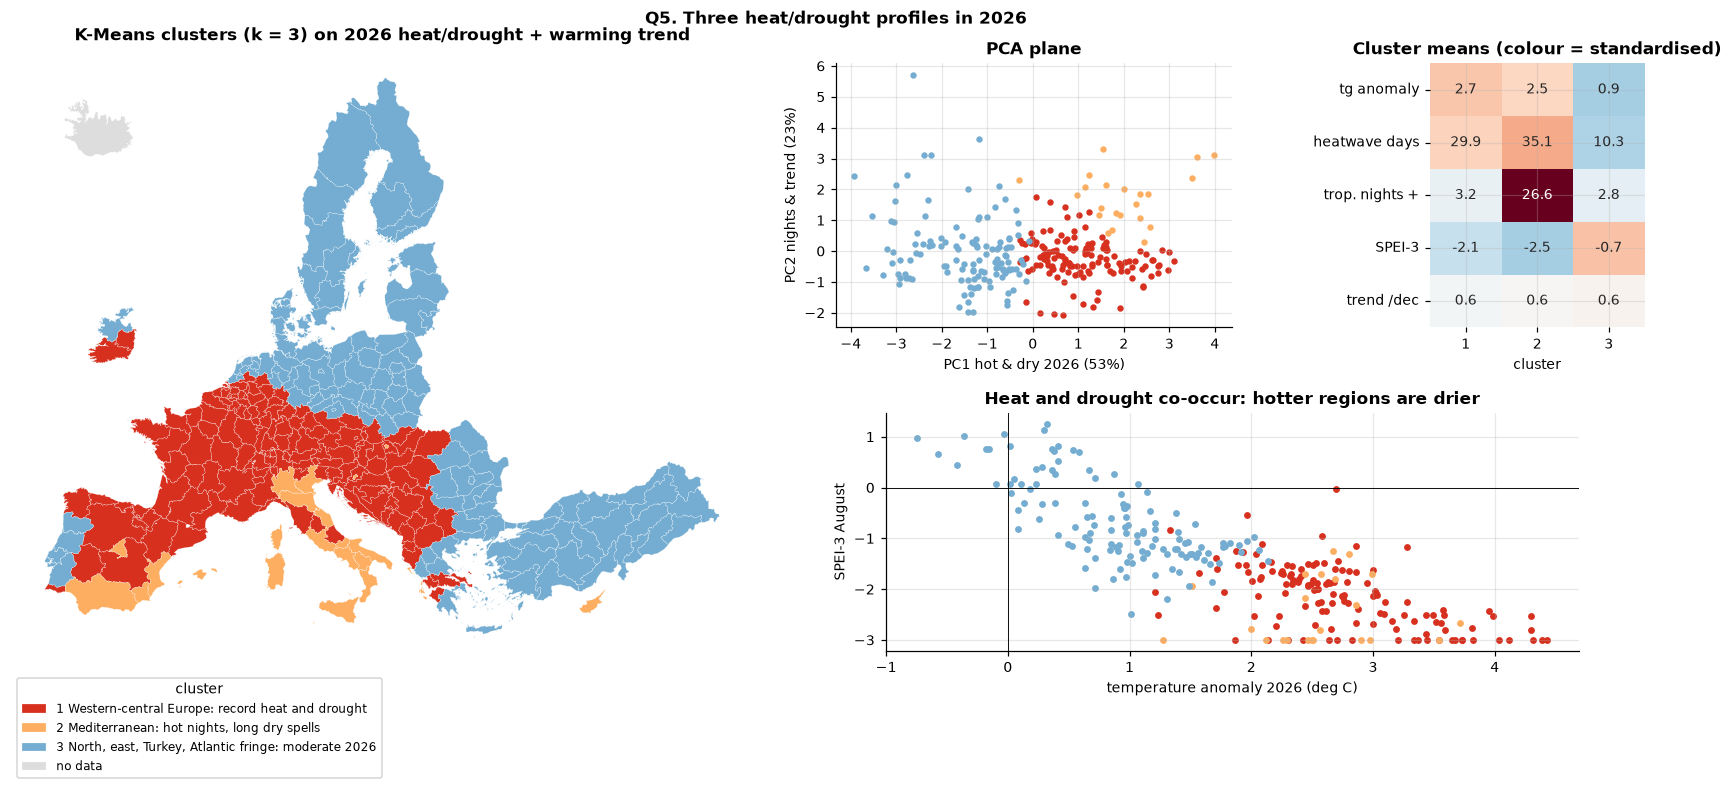

In [34]:
from matplotlib.colors import ListedColormap

shapes = viz.map_layer(regions).join(labels.map(cluster_names).rename("cluster_name"), on="region_id")
fig = plt.figure(figsize=(15, 6))
ax_map = fig.add_axes([0.0, 0.0, 0.45, 1.0])
viz.plot_map(shapes, "cluster_name", ax_map, categorical=True, label="cluster",
             cmap=ListedColormap(list(cluster_colors.values())),
             title=f"K-Means clusters (k = {K}) on 2026 heat/drought + warming trend",
             legend_kwds={"loc": "upper left", "bbox_to_anchor": (0.0, 0.0)})  # legend below the map
ax_pca = fig.add_axes([0.5, 0.55, 0.24, 0.4])
for c, color in cluster_colors.items():
    sel = labels == c
    ax_pca.scatter(pcs.loc[sel, "pc1"], pcs.loc[sel, "pc2"], s=10, color=color, label=cluster_names[c][:1])
ax_pca.set_xlabel(f"PC1 hot & dry 2026 ({clu.pca_.explained_variance_ratio_[0]:.0%})")
ax_pca.set_ylabel(f"PC2 nights & trend ({clu.pca_.explained_variance_ratio_[1]:.0%})"); ax_pca.set_title("PCA plane")
ax_heat = fig.add_axes([0.86, 0.55, 0.13, 0.4])
z_prof = (profiles[features] - features_table[features].mean()) / features_table[features].std()
short = {"tg_anomaly_2026": "tg anomaly", "heatwave_days_2026": "heatwave days", "tropical_nights_change_2026": "trop. nights +",
         "spei3_aug_2026": "SPEI-3", "tg_trend_decade": "trend /dec"}
sns.heatmap(z_prof.T.rename(index=short), annot=profiles[features].T.round(1), fmt="", cmap="RdBu_r", center=0, cbar=False, ax=ax_heat)
ax_heat.set_title("Cluster means (colour = standardised)"); ax_heat.set_xlabel("cluster")
ax_sc = fig.add_axes([0.53, 0.06, 0.42, 0.36])
for c, color in cluster_colors.items():
    sel = features_table.index.isin(labels.index[labels == c])
    ax_sc.scatter(features_table.loc[sel, "tg_anomaly_2026"], features_table.loc[sel, "spei3_aug_2026"], s=12, color=color)
ax_sc.axhline(0, color="black", linewidth=0.6); ax_sc.axvline(0, color="black", linewidth=0.6)
ax_sc.set_xlabel(f"temperature anomaly {YEAR} (deg C)"); ax_sc.set_ylabel("SPEI-3 August")
ax_sc.set_title("Heat and drought co-occur: hotter regions are drier")
fig.suptitle(f"Q5. Three heat/drought profiles in {YEAR}", fontweight="bold", y=1.03)
viz.save(fig, FIG, "Q5_clusters")

# 5. Export for Power BI
We export the tables used by the dashboard: stable column names, a calendar table, the daily 2026 data for the date filter and simplified region boundaries for the map.

`daily_2026.csv` also includes a daily climatology (the 1991-2020 mean of each calendar day, smoothed over 31 days), so that the dashboard can show the 2026 anomaly day by day for any selected period.

In [35]:
from climate_europe.export.powerbi import PowerBIExporter

# daily climatology of tg for each calendar day (Feb 29 dropped), smoothed with a centred circular 31-day window
ref_daily = daily[daily["date"].dt.year.between(*REF)].assign(md=lambda d: d["date"].dt.strftime("%m-%d"))
ref_daily = ref_daily[ref_daily["md"] != "02-29"]
clim = ref_daily.pivot_table(index="md", columns="region_id", values="tg", aggfunc="mean", observed=True)
clim = pd.concat([clim.iloc[-15:], clim, clim.iloc[:15]]).rolling(31, center=True).mean().iloc[15:-15]
clim_long = clim.stack().rename("tg_clim").reset_index()

daily_year = daily[daily["date"].dt.year == YEAR].assign(region_id=lambda d: d["region_id"].astype(str))
daily_year = daily_year.assign(md=daily_year["date"].dt.strftime("%m-%d")).merge(clim_long, on=["md", "region_id"], how="left")
daily_year["tg_anomaly"] = daily_year["tg"] - daily_year["tg_clim"]
daily_year = daily_year.drop(columns="md")

regions_out = regions.drop(columns="geometry").merge(labels.rename("cluster").reset_index(), on="region_id", how="left")
regions_out["cluster_name"] = regions_out["cluster"].map(cluster_names)
regions_out = (regions_out
               .merge(tg_trend[["region_id", "slope_decade", "p_value", "significant_fdr"]]
                      .rename(columns={"slope_decade": "tg_trend_decade", "p_value": "tg_trend_p", "significant_fdr": "tg_trend_significant"}), on="region_id")
               .merge(z2026[["region_id", "zscore", "rank", "is_record"]]
                      .rename(columns={"zscore": "tg_zscore_2026", "rank": "tg_rank_2026", "is_record": "tg_record_2026"}), on="region_id", how="left")
               .merge(departure[["region_id", "residual_z"]].rename(columns={"residual_z": "tg_departure_from_trend_2026"}), on="region_id", how="left"))

regions_out[["cluster", "tg_rank_2026"]] = regions_out[["cluster", "tg_rank_2026"]].astype("Int64")  # Iceland has no 2026 value

trends_out = pd.concat([t.assign(variable=v) for v, t in trends.items()])[
    ["region_id", "variable", "slope_decade", "tau", "p_value", "significant", "significant_fdr", "n"]]
pca_out = pcs.join(labels).reset_index()

tables = {
    "regions": regions_out,
    "indicators": indicators,
    "trends": trends_out,
    "europe_summary": europe.reset_index(),
    "daily_2026": daily_year[["region_id", "date", "tg", "tn", "tx", "rr", "tg_clim", "tg_anomaly"]],
    "pca": pca_out,
    "cluster_profiles": profiles.reset_index().assign(cluster_name=lambda d: d["cluster"].map(cluster_names)),
    "calendar": PowerBIExporter.build_calendar(f"{YEAR}-01-01", daily_year["date"].max().strftime("%Y-%m-%d")),
}
exporter = PowerBIExporter(cfg)
exporter.export_all(tables)
exporter.export_map(regions)

19:20:12 | export.powerbi | INFO | regions.csv: 281 rows x 15 columns


19:20:13 | export.powerbi | INFO | indicators.csv: 13207 rows x 21 columns


19:20:13 | export.powerbi | INFO | trends.csv: 2529 rows x 9 columns


19:20:13 | export.powerbi | INFO | europe_summary.csv: 47 rows x 10 columns


19:20:13 | export.powerbi | INFO | daily_2026.csv: 76713 rows x 8 columns


19:20:13 | export.powerbi | INFO | pca.csv: 280 rows x 4 columns


19:20:13 | export.powerbi | INFO | cluster_profiles.csv: 3 rows x 12 columns


19:20:13 | export.powerbi | INFO | calendar.csv: 273 rows x 9 columns


19:20:14 | export.powerbi | INFO | regions_map.geojson and regions_map.topojson written (281 regions)


**Power BI model** (details in `docs/powerbi_guide.md`). `regions` is the dimension table, with one row per `region_id`, linked one-to-many to `indicators`, `daily_2026`, `trends` and `pca`. `calendar[date]` is linked to `daily_2026[date]` and drives the date filter. The Shape Map visual uses `regions_map.topojson`, with `region_id` as key.

# 6. Conclusion

**Answers to the research questions**

* **Q1. Trend.** Over 1980-2025, summer temperature increased significantly in about 98 % of the 281 regions (Mann-Kendall test, FDR-corrected). The median Sen slope is about +0.57 °C per decade (from about 0.1 to 1.6 depending on the region), and about +0.6 °C per decade for Europe as a whole, i.e. roughly +2.6 °C in 46 years. Maximum temperatures warm faster than minimum temperatures, and the number of days above the local 90th percentile increases by about 2.5 days per decade.
* **Q2. The 2026 anomaly.** Summer 2026 was the second warmest European summer since 1980, practically tied with 2024, and the second driest according to SPEI, after 2003. More than half of the regions were beyond 2 standard deviations of the 1991-2020 normal, and about 110 regions had their warmest summer on record. The core of the event was western France and northern Spain, with z-scores close to 5.
* **Q3. Exception or continuation?** At European scale, 2026 is mostly the *continuation* of the trend. The trend line alone predicts an anomaly of about +1.2 °C, and 2026 lies only about one standard deviation above it, less than 2022 or 2024 (about 1.5 standard deviations each). At regional level, however, it is an *exception on top of the trend* in France, Switzerland and Spain, often more than 2 standard deviations above the trend, while Turkey and the north-east (Baltic states, Poland) stayed close to or below their trend. In other words, an ordinary summer today is already as warm as an extreme summer of the 1980s.
* **Q4. Geography.** Warming is fastest in southern and central Europe (about 0.6 °C per decade) and slowest north of 55°N (about 0.36 °C per decade). The gradient is significant (Kruskal-Wallis; Spearman ρ ≈ −0.33), although the p-values are optimistic because of spatial autocorrelation.
* **Q5. Profiles.** The clustering gives three types of regions: (1) western and central Europe, with record heat, long heatwaves and severe drought; (2) a Mediterranean group (Italy, southern and eastern Spain, coastal areas), where 2026 mainly brought many more tropical nights and very long dry spells; (3) the north, the east, Turkey and the Atlantic fringe (Portugal, North Sea coast), where 2026 was more moderate. Heat and drought clearly occur together (Spearman ≈ −0.8 with SPEI, and the link holds with precipitation alone), and the drying trend comes from a higher evaporative demand rather than from less summer rain.

**Limits**
* The 2026 monthly updates are provisional and based on fewer stations; the values may change with the next full E-OBS release.
* The Thornthwaite formula ignores radiation, wind and humidity, so our drought index is only SPEI-like and has not been validated against SPEIbase. In arid regions, summer SPEI is driven mostly by temperature, and the values are capped at ±3.
* The quality of E-OBS depends on station density, which is lower in Turkey, the Balkans, Iceland and mountain areas. Regional means also smooth out local extremes: a regional mean rarely reaches 35 °C even when individual stations do.
* Neighbouring regions are spatially correlated, so significance levels and silhouette scores are optimistic.
* The Mann-Kendall test assumes independent years; we checked this assumption (the lag-1 autocorrelation of the detrended series is close to 0).

**Perspectives**
* Use the E-OBS ensemble spread to add uncertainty ranges to the regional values, and validate the drought index against SPEIbase over 1980-2024.
* Estimate PET with Penman-Monteith using ERA5 radiation and wind, and add soil moisture or vegetation (NDVI) data to study agricultural drought.
* Include the UK (ITL regions) and impact data such as excess mortality or crop yields, to link the climate profiles to their consequences.